## The objective of this notebook is to design hypotheses and perform EDA 

In [86]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_ind

In [87]:
# Reading cleaned data

data = pd.read_csv("cleaned_data/processed_data_v1.csv")
data_eda = (
    data
    .rename(columns = {"Healthy":"Disease_State"})
    .sort_values(by = ["Disease_State"])
    .reset_index(drop = True)
)

F:\Python\lib\site-packages\IPython\core\interactiveshell.py:3457: DtypeWarning: Columns (1) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [88]:
data_eda

,Disease_State,Cancer,hsa-miR-486-5p,hsa-miR-451a,hsa-miR-92a-3p,hsa-miR-181a-5p,hsa-miR-99a-5p,hsa-miR-21-5p,hsa-miR-26a-5p,hsa-miR-22-3p,...,hsa-miR-3658,hsa-miR-3620-5p,hsv1-miR-H4-5p,hsa-miR-4798-3p,hsa-miR-5702,hsa-miR-548ao-5p,hsa-miR-4790-5p,hsa-miR-4684-5p,hsa-miR-4539,hsa-miR-10525-3p
0,0.0,False,4382.03,20197.87,2742.05,26685.93,189688.17,1508.20,4230.72,90675.11,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,False,916.51,3.24,67163.77,56893.55,9.72,149564.01,80458.33,48540.62,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,False,1131.59,543.49,68046.34,81203.58,39.54,23735.96,96816.65,15205.46,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,False,1357.35,180.81,67620.79,48461.67,113.72,54721.72,107791.57,12507.52,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,False,15873.02,0.00,65759.64,106575.96,0.00,52154.20,106575.96,29478.46,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1467,1.0,True,55173.47,113667.48,3746.34,2092.63,1843.42,48892.48,14139.95,4330.54,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1468,1.0,True,103939.21,109185.11,23537.64,4145.40,5559.66,39916.35,31399.16,8365.88,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1469,1.0,True,246153.09,179855.66,63952.44,2233.44,4466.87,13825.52,8026.65,5378.96,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1470,1.0,True,216973.60,211036.70,37167.79,1974.43,3485.75,12320.93,11268.31,4128.16,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [89]:
# Defining a function to plot the miRNA expression values of a select miRNA for Healthy vs Cancer samples

def scatter_plot(mirna: str):
    
    healthy = data_eda[data_eda["Disease_State"]==0]
    cancer = data_eda[data_eda["Disease_State"]==1]

    plt.figure(figsize = (10,8))
    plt.scatter(healthy.index,healthy[f"{mirna}"],color='blue', marker='s', label= "Healthy samples")
    plt.scatter(cancer.index,cancer[f"{mirna}"],color='orange', marker='o', label= "Cancer samples")
    plt.xlabel("Sample number")
    plt.ylabel(f"miRNA RPM for {mirna}")
    plt.title(f"{mirna} expression patterns for healthy and cancer samples")
    plt.legend()
    plt.show()

In [90]:
# Defining a function to perform Welch t-test which will help us evaluate our hypothesis

def welch_t_test(mirna):

    healthy = data_eda[data_eda["Disease_State"]==0][mirna]
    cancer = data_eda[data_eda["Disease_State"]==1][mirna]
    
    # Log2 transform expression values (This is because miRNA values can have extreme outliers which can skew the mean)
    # 0.5 is a standard constant added to handle 0s in the miRNA data
    healthy_log = np.log2(healthy + 0.5)
    cancer_log = np.log2(cancer + 0.5)

    # Welch's two-sample t-test
    result = ttest_ind(
        cancer_log,
        healthy_log,
        equal_var=False,
        alternative="two-sided"
    )

    mean_difference = cancer_log.mean() - healthy_log.mean()

    return mean_difference,result.pvalue

### Hypothesis 1: mir-21 is usually heavily upregulated in several forms of cancer. We hypothesize that mir-21 will be universally upregulated

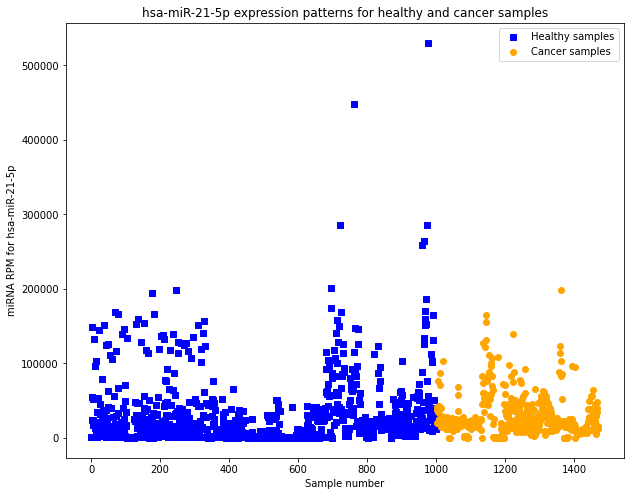

In [91]:
# Generating scatter plot for hypothesis 1

scatter_plot("hsa-miR-21-5p")

In [92]:
# Comparing the mean of healthy vs cancer samples with respect to hsa-miR-21-5p RPMs

diff,p_val = welch_t_test("hsa-miR-21-5p")
print("The mean difference between thr groups is:",diff)
print("The p-value between the groups is:",p_val)

The mean difference between thr groups is: 0.9509190093762925
The p-value between the groups is: 1.730380291121147e-08


### Hypothesis 2: mir-155 is usually heavily upregulated in several forms of cancer. We hypothesize that mir-155 will be universally upregulated

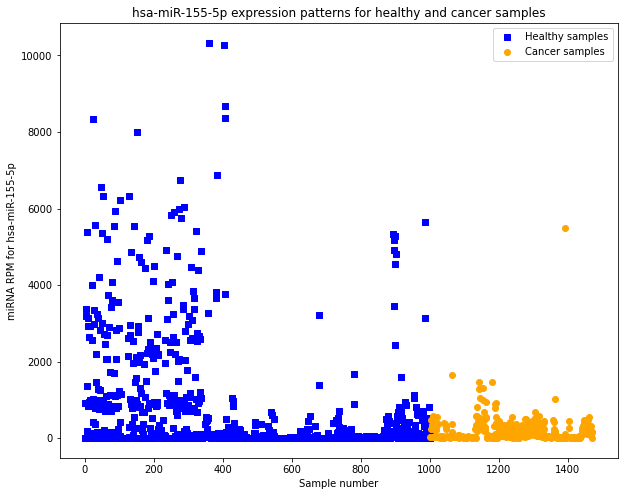

In [93]:
# Generating scatter plot for hypothesis 2

scatter_plot("hsa-miR-155-5p")

In [94]:
# Comparing the mean of healthy vs cancer samples with respect to hsa-miR-155-5p RPMs

diff,p_val = welch_t_test("hsa-miR-155-5p")
print("The mean difference between the groups is:",diff)
print("The p-value between the groups is:",p_val)

The mean difference between the groups is: 0.8593957628934623
The p-value between the groups is: 1.6889864860830566e-06


### Hypothesis 3: mir-222 is usually heavily upregulated in several forms of cancer. We hypothesize that mir-222 will be universally upregulated

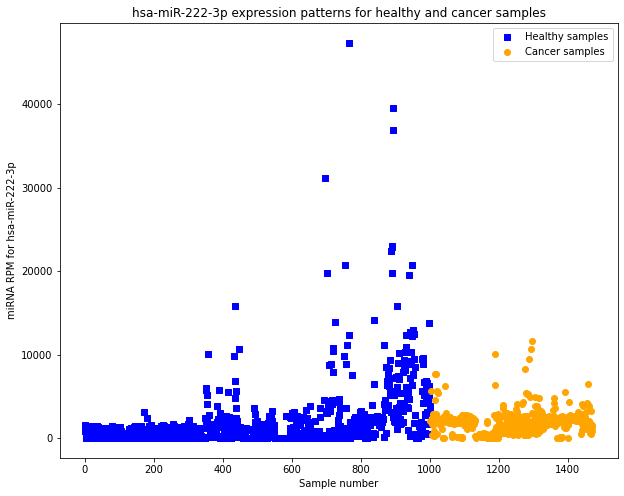

In [95]:
# Generating scatter plot for hypothesis 3

scatter_plot("hsa-miR-222-3p")

In [96]:
# Comparing the mean of healthy vs cancer samples with respect to hsa-miR-222-3p RPMs

diff,p_val = welch_t_test("hsa-miR-222-3p")
print("The mean difference between the groups is:",diff)
print("The p-value between the groups is:",p_val)

The mean difference between the groups is: 1.6820787250547617
The p-value between the groups is: 3.0752253843249242e-24


### Hypothesis 4: Members of the let-7 family is usually heavily downregulated in several forms of cancer. We hypothesize that let-7a will be universally downregulated

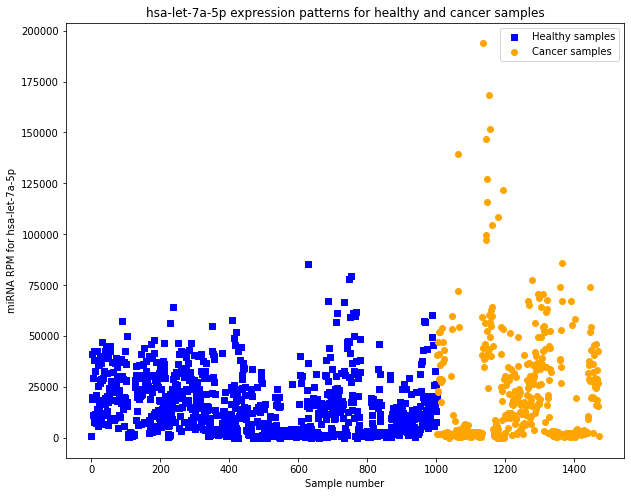

In [97]:
# Generating scatter plot for hypothesis 4

scatter_plot("hsa-let-7a-5p")

In [98]:
# Comparing the mean of healthy vs cancer samples with respect to hsa-let-7a-5p RPMs

diff,p_val = welch_t_test("hsa-let-7a-5p")
print("The mean difference between the groups is:",diff)
print("The p-value between the groups is:",p_val)

The mean difference between the groups is: -0.10739626660425827
The p-value between the groups is: 0.48708144717616886


### Hypothesis 5: mir-26a family is usually downregulated in several forms of cancer. We hypothesize that mir-26a will be universally downregulated

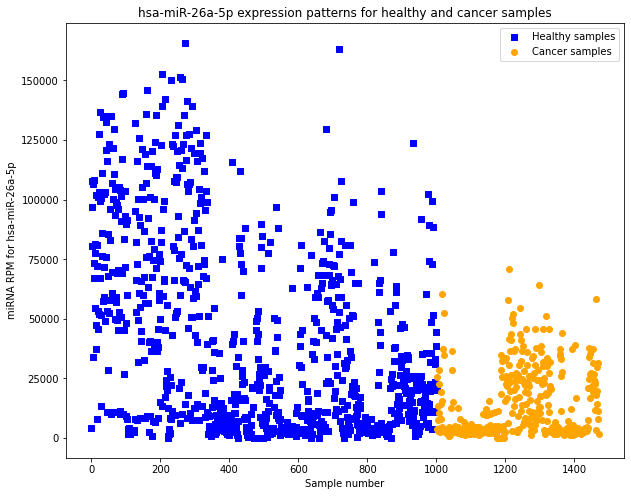

In [99]:
# Generating scatter plot for hypothesis 5

scatter_plot("hsa-miR-26a-5p")

In [100]:
# Comparing the mean of healthy vs cancer samples with respect to hsa-miR-26a-5p RPMs

diff,p_val = welch_t_test("hsa-miR-26a-5p")
print("The mean difference between the groups is:",diff)
print("The p-value between the groups is:",p_val)

The mean difference between the groups is: -1.335354018859677
The p-value between the groups is: 2.0497640051799892e-21
